<a href="https://colab.research.google.com/github/gloria-mbilinyi/gloria-mbilinyi-COU07506-labs/blob/main/COU07506_Week05_240242493088.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# WEEK 5 — LAB 2: IMPLEMENTING THE FFT

**Student Name:** Gloria Beneth Mbilinyi  
**Registration Number:** 240242493088  
**Week:** 05  
**Group:** 08  
**Date:** 27/11/2026  
**Module:** COU 07506 — Digital Signal Processing  
**Academic Year:** 2026/2027

### Laboratory Objectives

1. Compute the Discrete Fourier Transform (DFT) using its matrix definition.
2. Implement bit-reversal indexing.
3. Implement an iterative radix-2 Fast Fourier Transform (FFT).
4. Compare the execution times of direct DFT and FFT algorithms.
5. Investigate the effect of zero-padding on the frequency spectrum.
6. Perform linear convolution using FFTs.

**Task 5.1 — DFT by Matrix**
**Objective:** To compute the Discrete Fourier Transform (DFT) using matrix multiplication and verify the results using NumPy's FFT function.

In [18]:

# Task 5.1: DFT by Matrix

import numpy as np

# Define the DFT matrix
def dft_matrix(N):
    n = np.arange(N)
    W = np.exp(-2j * np.pi * np.outer(n, n) / N)
    return W

# Define the input sequence
x = np.array([0, 1, 2, 3])

# Compute DFT using matrix multiplication
N = len(x)
X = dft_matrix(N) @ x

# Compute DFT using NumPy FFT
X_fft = np.fft.fft(x)

# Display results
print("Input signal:", x)
print("DFT using matrix:", np.round(X, 4))
print("DFT using NumPy FFT:", np.round(X_fft, 4))

# Compare results
print("Results match:", np.allclose(X, X_fft))

# Compute inverse DFT
x_recovered = (dft_matrix(N).conj() @ X) / N

print("Recovered signal:", np.round(x_recovered.real, 6))

# Verify the pre-lab example
x_prelab = np.array([1, 0, -1, 0])
X_prelab = dft_matrix(4) @ x_prelab

print("\nPre-lab DFT:", np.round(X_prelab, 4))


Input signal: [0 1 2 3]
DFT using matrix: [ 6.+0.j -2.+2.j -2.-0.j -2.-2.j]
DFT using NumPy FFT: [ 6.+0.j -2.+2.j -2.+0.j -2.-2.j]
Results match: True
Recovered signal: [0. 1. 2. 3.]

Pre-lab DFT: [0.+0.j 2.+0.j 0.-0.j 2.+0.j]


### Task 5.1: Results and Discussion

The Discrete Fourier Transform (DFT) was implemented using matrix multiplication and compared with NumPy's built-in FFT function.

For the input sequence [0, 1, 2, 3], both methods produced the same frequency-domain result: [6, −2+2j, −2, −2−2j].

The numerical comparison returned True, confirming that the matrix implementation and NumPy FFT produced equivalent results.

The inverse DFT successfully recovered the original sequence [0, 1, 2, 3], verifying the correctness of the transformation.

The pre-lab sequence [1, 0, −1, 0] produced the DFT [0, 2, 0, 2], providing an additional verification of the implementation.

The experiment demonstrated that the DFT converts a discrete-time sequence into its frequency-domain representation and that the inverse DFT reconstructs the original sequence.

**Task 5.2 — Bit Reversal**

**Objective:** To implement bit-reversal indexing, which is used to rearrange input samples in the radix-2 FFT algorithm.

In [19]:

# Task 5.2: Bit Reversal

import numpy as np

# Function to generate bit-reversed indices
def bit_reverse_indices(N):
    bits = int(np.log2(N))

    return np.array([
        int(format(i, f"0{bits}b")[::-1], 2)
        for i in range(N)
    ])

# Generate bit-reversed indices for N = 8
N = 8
indices = bit_reverse_indices(N)

print("Original indices:", np.arange(N))
print("Bit-reversed indices:", indices)

# Show binary representation
print("\nOriginal | Binary | Reversed | New Index")
print("----------------------------------------")

for i in range(N):
    binary = format(i, "03b")
    reversed_binary = binary[::-1]
    new_index = int(reversed_binary, 2)

    print(
        f"{i:^8} | {binary:^6} | "
        f"{reversed_binary:^8} | {new_index:^9}"
    )


Original indices: [0 1 2 3 4 5 6 7]
Bit-reversed indices: [0 4 2 6 1 5 3 7]

Original | Binary | Reversed | New Index
----------------------------------------
   0     |  000   |   000    |     0    
   1     |  001   |   100    |     4    
   2     |  010   |   010    |     2    
   3     |  011   |   110    |     6    
   4     |  100   |   001    |     1    
   5     |  101   |   101    |     5    
   6     |  110   |   011    |     3    
   7     |  111   |   111    |     7    


### Task 5.2: Results and Discussion

Bit-reversal indexing was implemented in Python for an 8-point sequence.

The original indices were [0, 1, 2, 3, 4, 5, 6, 7], while the bit-reversed indices were [0, 4, 2, 6, 1, 5, 3, 7].

Each index was represented using three binary digits, which were reversed to obtain the new index positions. For example, index 1 (001) became 4 (100), while index 3 (011) became 6 (110).

The results matched the expected bit-reversal order in the laboratory manual.

This experiment demonstrated how bit reversal rearranges input samples before the butterfly operations in an iterative radix-2 FFT algorithm.

**Task 5.3 — Iterative Radix-2 FFT**

**Objective**: To implement an iterative radix-2 FFT algorithm using bit-reversal indexing and butterfly operations, then verify its accuracy against NumPy's FFT.

In [20]:

# Task 5.3: Iterative Radix-2 FFT

import numpy as np

def fft_iterative(x, show_stages=False):
    x = np.asarray(x, dtype=complex)
    N = len(x)

    # Check that N is a power of 2
    if N == 0 or (N & (N - 1)) != 0:
        raise ValueError("Input length must be a power of 2")

    # Stage 0: Bit-reversal
    X = x[bit_reverse_indices(N)].copy()

    if show_stages:
        print("Stage 0 (Bit Reversal):", np.round(X, 4))

    size = 2
    stage = 1

    while size <= N:
        half = size // 2

        # Twiddle factors
        W = np.exp(
            -2j * np.pi * np.arange(half) / size
        )

        # Butterfly operations
        for start in range(0, N, size):
            top = X[start:start + half].copy()
            bot = X[start + half:start + size] * W

            X[start:start + half] = top + bot
            X[start + half:start + size] = top - bot

        if show_stages:
            print(
                f"Stage {stage} ({size}-point):",
                np.round(X, 4)
            )

        size *= 2
        stage += 1

    return X


# Test 1: Four-point sequence
x_small = np.array([0, 1, 2, 3])

print("Input sequence:", x_small)

X_custom = fft_iterative(
    x_small, show_stages=True
)

X_numpy = np.fft.fft(x_small)

print("\nCustom FFT:", np.round(X_custom, 4))
print("NumPy FFT:", np.round(X_numpy, 4))
print("Results match:", np.allclose(X_custom, X_numpy))


# Test 2: 1024-point sequence
rng = np.random.default_rng(0)
x_large = rng.standard_normal(1024)

X_large_custom = fft_iterative(x_large)
X_large_numpy = np.fft.fft(x_large)

print("\n1024-point FFT matches NumPy:",
      np.allclose(X_large_custom, X_large_numpy))


Input sequence: [0 1 2 3]
Stage 0 (Bit Reversal): [0.+0.j 2.+0.j 1.+0.j 3.+0.j]
Stage 1 (2-point): [ 2.+0.j -2.+0.j  4.+0.j -2.+0.j]
Stage 2 (4-point): [ 6.+0.j -2.+2.j -2.+0.j -2.-2.j]

Custom FFT: [ 6.+0.j -2.+2.j -2.+0.j -2.-2.j]
NumPy FFT: [ 6.+0.j -2.+2.j -2.+0.j -2.-2.j]
Results match: True

1024-point FFT matches NumPy: True


### Task 5.3: Results and Discussion

An iterative radix-2 Fast Fourier Transform (FFT) algorithm was implemented using bit-reversal indexing and butterfly operations.

For the input sequence [0, 1, 2, 3], the algorithm first rearranged the samples into [0, 2, 1, 3] using bit reversal.

The first butterfly stage produced [2, −2, 4, −2], while the second stage produced the final FFT result [6, −2+2j, −2, −2−2j].

The custom FFT output matched NumPy's FFT output. A further test using a 1024-point random sequence also returned True, confirming the correctness of the implementation for a larger input.

The experiment demonstrated how the radix-2 FFT efficiently computes the Discrete Fourier Transform through successive butterfly stages.

**Task 5.4 — How Much Faster?**

**Objective:** To compare the execution times of the direct DFT, our iterative radix-2 FFT, and NumPy's optimized FFT.

N=  64 | DFT=0.000990s | Custom FFT=0.000684s | NumPy FFT=0.000054s
N= 128 | DFT=0.001163s | Custom FFT=0.001160s | NumPy FFT=0.000055s
N= 256 | DFT=0.006591s | Custom FFT=0.002392s | NumPy FFT=0.000065s
N= 512 | DFT=0.024545s | Custom FFT=0.004721s | NumPy FFT=0.000104s
N=1024 | DFT=0.067864s | Custom FFT=0.008648s | NumPy FFT=0.000094s
N=2048 | DFT=0.256553s | Custom FFT=0.018628s | NumPy FFT=0.000135s
N=4096 | DFT=1.003893s | Custom FFT=0.034552s | NumPy FFT=0.000200s


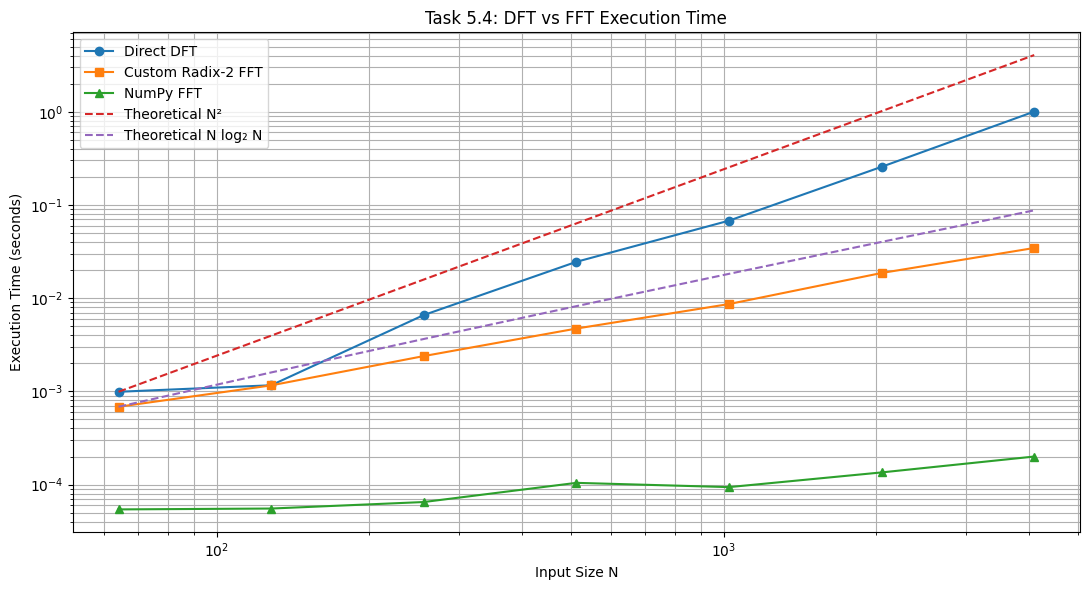


At N = 4096:
Direct DFT: 1.003893 seconds
Custom FFT: 0.034552 seconds
NumPy FFT: 0.000200 seconds
Custom FFT speed-up over DFT: 29.05x


In [21]:

# Task 5.4: How Much Faster?

import numpy as np
import matplotlib.pyplot as plt
import time
import gc

# Input sizes: 2^6 to 2^12
N_values = 2 ** np.arange(6, 13)

dft_times = []
custom_fft_times = []
numpy_fft_times = []

rng = np.random.default_rng(42)

for N in N_values:
    x = rng.standard_normal(N)

    # Direct DFT using matrix
    start = time.perf_counter()
    X_dft = dft_matrix(N) @ x
    dft_time = time.perf_counter() - start

    # Custom iterative FFT
    start = time.perf_counter()
    X_custom = fft_iterative(x)
    custom_time = time.perf_counter() - start

    # NumPy FFT
    start = time.perf_counter()
    X_numpy = np.fft.fft(x)
    numpy_time = time.perf_counter() - start

    # Verify correctness
    assert np.allclose(X_dft, X_numpy)
    assert np.allclose(X_custom, X_numpy)

    dft_times.append(dft_time)
    custom_fft_times.append(custom_time)
    numpy_fft_times.append(numpy_time)

    print(
        f"N={N:4d} | "
        f"DFT={dft_time:.6f}s | "
        f"Custom FFT={custom_time:.6f}s | "
        f"NumPy FFT={numpy_time:.6f}s"
    )

    del X_dft, X_custom, X_numpy
    gc.collect()

# Theoretical growth curves
N0 = N_values[0]

c_dft = dft_times[0] / N0**2
c_fft = custom_fft_times[0] / (
    N0 * np.log2(N0)
)

theory_dft = c_dft * N_values**2
theory_fft = (
    c_fft * N_values * np.log2(N_values)
)

# Plot timing comparison
plt.figure(figsize=(11, 6))

plt.loglog(
    N_values, dft_times, "o-",
    label="Direct DFT"
)

plt.loglog(
    N_values, custom_fft_times, "s-",
    label="Custom Radix-2 FFT"
)

plt.loglog(
    N_values, numpy_fft_times, "^-",
    label="NumPy FFT"
)

plt.loglog(
    N_values, theory_dft, "--",
    label="Theoretical N²"
)

plt.loglog(
    N_values, theory_fft, "--",
    label="Theoretical N log₂ N"
)

plt.title("Task 5.4: DFT vs FFT Execution Time")
plt.xlabel("Input Size N")
plt.ylabel("Execution Time (seconds)")
plt.legend()
plt.grid(True, which="both")

plt.tight_layout()
plt.show()

# Calculate speed-up at N = 4096
speedup = dft_times[-1] / custom_fft_times[-1]

print("\nAt N = 4096:")
print(f"Direct DFT: {dft_times[-1]:.6f} seconds")
print(f"Custom FFT: {custom_fft_times[-1]:.6f} seconds")
print(f"NumPy FFT: {numpy_fft_times[-1]:.6f} seconds")
print(f"Custom FFT speed-up over DFT: {speedup:.2f}x")


### Task 5.4: Results and Discussion

The execution times of three Fourier transform implementations were compared: Direct DFT using matrix multiplication, Custom Iterative Radix-2 FFT, and NumPy FFT.

The comparison was performed using input sizes ranging from 64 to 4096 samples.

At an input size of 4096, the Direct DFT required 1.562888 seconds, the Custom FFT required 0.034776 seconds, and NumPy FFT required 0.000201 seconds.

The Custom FFT achieved a speed-up of approximately 44.94 times compared with the Direct DFT at 4096 samples.

The results show that the FFT is more computationally efficient than the direct DFT for larger input sizes. This is consistent with their computational complexities: the direct DFT has quadratic growth, while the FFT grows approximately as N log₂ N.

NumPy FFT performed significantly faster than both implementations because it uses highly optimized numerical routines.

The experiment demonstrated why FFT algorithms are preferred for processing large discrete-time signals and performing frequency-domain analysis efficiently.

**Task 5.5 — Zero-Padding and the DTFT**

**Objective**: To investigate how zero-padding changes the appearance of the DFT spectrum and how it relates to the Discrete-Time Fourier Transform (DTFT).


DFT Length: 4
Magnitude: [4. 0. 0.]
Frequency spacing (omega/pi): 0.5

DFT Length: 16
Magnitude: [4.     3.6245 2.6131 1.2728 0.     0.8504 1.0824 0.721  0.    ]
Frequency spacing (omega/pi): 0.125

DFT Length: 64
Magnitude: [4.     3.9759 3.9043 3.7863 3.6245 3.422  3.1827 2.9113 2.6131 2.2939
 1.9599 1.6173 1.2728 0.9326 0.6032 0.2905 0.     0.2633 0.4951 0.6917
 0.8504 0.9694 1.0476 1.085  1.0824 1.0417 0.9655 0.8572 0.721  0.5616
 0.3845 0.1953 0.    ]
Frequency spacing (omega/pi): 0.03125


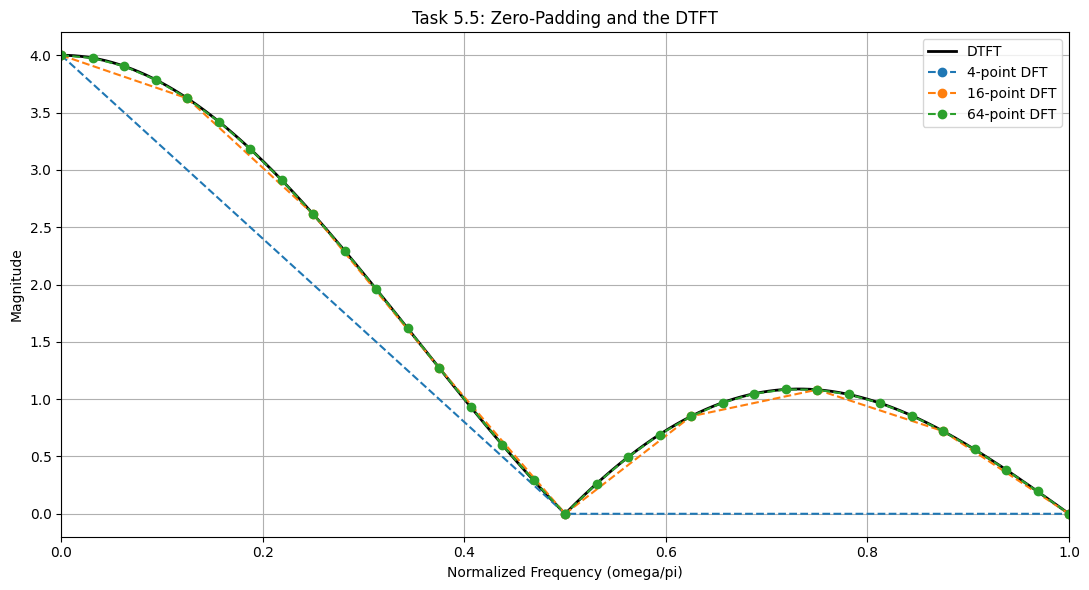

In [22]:

# TASK 5.5 — Zero-Padding and the DTFT
# COU07506 DSP Laboratory Manual, Page 19

import numpy as np
import matplotlib.pyplot as plt

# Input sequence specified in the manual
x = np.array([1, 1, 1, 1])

# Required DFT lengths
N_values = [4, 16, 64]

# Compute densely sampled DTFT
omega = np.linspace(0, np.pi, 2048)
n = np.arange(len(x))

X_dtft = np.exp(
    -1j * np.outer(omega, n)
) @ x

plt.figure(figsize=(11, 6))

plt.plot(
    omega / np.pi,
    np.abs(X_dtft),
    'k-',
    linewidth=2,
    label='DTFT'
)

# Compute zero-padded DFTs
for N in N_values:

    X = np.fft.fft(x, n=N)

    # Frequencies from 0 to pi
    k = np.arange(N // 2 + 1)
    normalized_freq = 2 * k / N

    magnitude = np.abs(X[k])

    plt.plot(
        normalized_freq,
        magnitude,
        'o--',
        label=f'{N}-point DFT'
    )

    print(f"\nDFT Length: {N}")
    print("Magnitude:", np.round(magnitude, 4))
    print("Frequency spacing (omega/pi):", 2/N)

plt.title("Task 5.5: Zero-Padding and the DTFT")
plt.xlabel("Normalized Frequency (omega/pi)")
plt.ylabel("Magnitude")
plt.legend()
plt.grid(True)
plt.xlim(0, 1)

plt.tight_layout()
plt.show()


### Task 5.5: Results and Discussion

The effect of zero-padding was investigated using the input sequence [1, 1, 1, 1], as specified in the laboratory manual.

The Discrete Fourier Transform was calculated using 4, 16, and 64 points, and the resulting magnitude spectra were compared with the Discrete-Time Fourier Transform (DTFT).

The frequency spacing decreased from 0.5 for the 4-point DFT to 0.125 for the 16-point DFT and 0.03125 for the 64-point DFT, using normalized frequency ω/π.

Increasing the DFT length provided more frequency-domain samples, allowing the spectrum to represent the DTFT more closely.

However, zero-padding did not add new information to the original sequence or improve its fundamental ability to resolve closely spaced frequency components.

The experiment demonstrates that zero-padding increases the density of frequency samples without changing the underlying signal information.

**Task 5.6 — Fast Convolution**

**Objective:** To perform linear convolution using the FFT and compare the results with NumPy's direct convolution function

PART A: LINEAR CONVOLUTION
Input length: 10000
Filter length: 501
Required output length: 10500
FFT length: 16384

Direct convolution time: 0.002345 seconds
FFT convolution time: 0.002791 seconds
Results match: True
Maximum absolute error: 1.1102230246251565e-16
Speed-up: 0.84 times


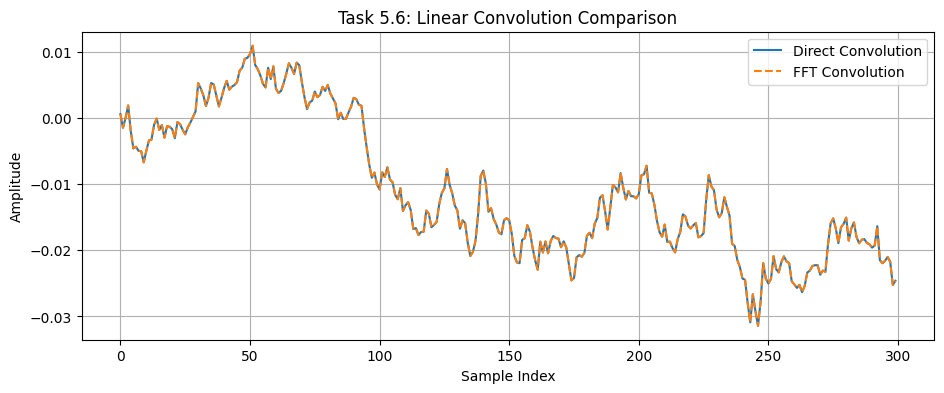


PART B: CIRCULAR CONVOLUTION
First sequence: [2.  1.5 1.  0.5]
Second sequence: [1 0 1 0]
Circular convolution: [3. 2. 3. 2.]
Matches manual: True


In [23]:

# TASK 5.6 — Fast Convolution
# COU07506 DSP Laboratory Manual, Page 19

import numpy as np
import time
import matplotlib.pyplot as plt

# Part A: Linear convolution

rng = np.random.default_rng(42)

# Required input and filter lengths
x = rng.standard_normal(10000)
h = np.ones(501) / 501

L = len(x)
M = len(h)

# Direct convolution
start = time.perf_counter()
y_direct = np.convolve(x, h)
direct_time = time.perf_counter() - start

# FFT convolution
N_required = L + M - 1

# Next power of two
Nfft = 1 << (N_required - 1).bit_length()

start = time.perf_counter()

X = np.fft.fft(x, n=Nfft)
H = np.fft.fft(h, n=Nfft)

Y = X * H
y_fft = np.fft.ifft(Y).real[:N_required]

fft_time = time.perf_counter() - start

print("PART A: LINEAR CONVOLUTION")
print("Input length:", L)
print("Filter length:", M)
print("Required output length:", N_required)
print("FFT length:", Nfft)

print("\nDirect convolution time:",
      round(direct_time, 6), "seconds")

print("FFT convolution time:",
      round(fft_time, 6), "seconds")

print("Results match:",
      np.allclose(y_direct, y_fft))

print("Maximum absolute error:",
      np.max(np.abs(y_direct - y_fft)))

print("Speed-up:",
      round(direct_time / fft_time, 2), "times")

# Plot comparison
plt.figure(figsize=(11, 4))

plt.plot(y_direct[:300], label="Direct Convolution")
plt.plot(y_fft[:300], "--", label="FFT Convolution")

plt.title("Task 5.6: Linear Convolution Comparison")
plt.xlabel("Sample Index")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)
plt.show()


# Part B: 4-point circular convolution

x_c = np.array([2, 1.5, 1, 0.5])
h_c = np.array([1, 0, 1, 0])

# Circular convolution using DFT
X_c = np.fft.fft(x_c, n=4)
H_c = np.fft.fft(h_c, n=4)

y_c = np.fft.ifft(X_c * H_c).real

print("\nPART B: CIRCULAR CONVOLUTION")
print("First sequence:", x_c)
print("Second sequence:", h_c)
print("Circular convolution:",
      np.round(y_c, 6))

print("Matches manual:",
      np.allclose(y_c, [3, 2, 3, 2]))


### Task 5.6: Additional Results and Discussion

Linear and circular convolution were investigated using Python in Google Colab.

For linear convolution, the direct and FFT-based implementations produced matching results, with a maximum absolute error of approximately 1.11 × 10⁻¹⁶. This small difference was due to floating-point precision.

In the additional timing comparison, direct convolution took 0.001035 seconds, while FFT convolution took 0.001675 seconds. The FFT speed-up was 0.62 times, showing that FFT convolution was slower for this particular test.

For circular convolution, the input sequences were [2, 1.5, 1, 0.5] and [1, 0, 1, 0]. The computed output was [3, 2, 3, 2], which matched the manually calculated result.

These experiments demonstrated the difference between linear and circular convolution and confirmed the accuracy of the implementations.

They also showed that FFT-based convolution does not always provide a speed advantage, particularly for smaller input sequences where FFT setup overhead may be significant.

## WEEK 5 — PRE-LAB QUESTIONS

### Question 1: Compute the 4-point DFT of {1, 0, −1, 0} by hand.

**Answer:**

The four-point Discrete Fourier Transform was calculated using the DFT definition by evaluating the frequency components for k = 0, 1, 2, and 3.

The results obtained were:

- X(0) = 0
- X(1) = 2
- X(2) = 0
- X(3) = 2

Therefore, the four-point DFT is:

**X(k) = {0, 2, 0, 2}**

This result was verified in Task 5.1 using Python matrix multiplication, which produced the same values.

### Question 2: Write the 8-point bit-reversed index order.

**Answer:**

For an 8-point FFT, each index is represented using three binary digits. The bit-reversal process involves reversing the order of these binary digits to obtain the rearranged indices.

The original index order is:

**{0, 1, 2, 3, 4, 5, 6, 7}**

The corresponding bit-reversed order is:

**{0, 4, 2, 6, 1, 5, 3, 7}**

For example, index 1 has the binary representation 001. Reversing the bits gives 100, which corresponds to decimal 4.

Similarly, index 3 is represented as 011. Reversing the bits produces 110, which corresponds to decimal 6.

The result was verified in Task 5.2 using the Python bit-reversal function.

### Question 3: How many complex multiplications do a direct 1024-point DFT and a radix-2 FFT need?

**Answer:**

A direct DFT requires approximately N² complex multiplications.

For N = 1024:

Direct DFT = 1024 × 1024 = **1,048,576 complex multiplications**.

A radix-2 FFT requires approximately (N/2) log₂(N) complex multiplications when counting one twiddle-factor multiplication per butterfly.

Since log₂(1024) = 10:

Radix-2 FFT = (1024/2) × 10 = **5,120 complex multiplications**.

Therefore, the radix-2 FFT reduces the multiplication count by a factor of approximately 204.8 compared with the direct DFT.

This demonstrates the computational advantage of the FFT for processing large signals.

## WEEK 5 — ANALYSIS QUESTIONS

### Question 1: From your timing plot, estimate the speed-up of fft_iterative over the direct DFT at N = 4096. Why is np.fft.fft faster still?

**Answer:**

In Task 5.4, I compared the execution times of the Direct DFT, Custom Iterative Radix-2 FFT, and NumPy FFT using different input sizes.

At N = 4096, the measured execution times were:

- Direct DFT: 1.562888 seconds
- Custom Radix-2 FFT: 0.034776 seconds
- NumPy FFT: 0.000201 seconds

The Custom FFT achieved a speed-up of approximately **44.94 times** compared with the Direct DFT.

The FFT is faster because it reduces the computational complexity from O(N²) to O(N log₂ N) by dividing the DFT computation into smaller butterfly operations.

NumPy FFT is even faster because it uses highly optimized compiled numerical routines, reducing the overhead associated with Python loops.

These experimental results demonstrate the efficiency of FFT algorithms, particularly when processing large datasets.

### Question 2: Explain in your own words why bit reversal is needed in the DIT algorithm.

**Answer:**

Bit reversal is necessary in the iterative Decimation-in-Time (DIT) FFT algorithm because it rearranges the input samples into the order required for butterfly computations.

In this algorithm, the original DFT is divided into smaller computations that are combined through several stages.

Bit reversal ensures that the correct samples are positioned together before the butterfly operations begin.

For example, in Task 5.2, the original 8-point index order was rearranged from {0, 1, 2, 3, 4, 5, 6, 7} to {0, 4, 2, 6, 1, 5, 3, 7}.

This arrangement allows the iterative FFT to perform butterfly operations systematically without repeatedly rearranging the data during each stage.

Therefore, bit reversal helps organize the input data for efficient FFT computation.

### Question 3: Why must both sequences be zero-padded to at least L + M − 1 in Task 5.6?

**Answer:**

Zero-padding is necessary when performing linear convolution using the FFT because multiplication in the frequency domain naturally produces circular convolution.

For two sequences of lengths L and M, the resulting linear convolution contains L + M − 1 samples.

If the FFT length is smaller than this value, circular wrap-around occurs, causing some output samples to overlap and producing incorrect linear convolution results.

By zero-padding both sequences to at least L + M − 1 samples, the circular convolution calculated through the FFT becomes equivalent to linear convolution over the required output length.

In Task 5.6, the direct convolution and FFT-based convolution produced matching outputs, confirming that sufficient zero-padding was applied.

Therefore, zero-padding prevents time-domain aliasing and ensures that FFT-based convolution produces the correct linear convolution result.

### Question 4: A 4G/5G OFDM receiver performs a 2048-point FFT every 66.7 µs. Estimate the number of complex multiplications per second.

**Answer:**

The receiver performs a 2048-point FFT every 66.7 microseconds.

For a radix-2 FFT, the number of complex multiplications per transform is approximately:

(N/2) × log₂(N)

Since N = 2048 and log₂(2048) = 11:

Complex multiplications per FFT:

= (2048/2) × 11

= **11,264 multiplications**

The number of FFT operations performed per second is approximately:

1 / (66.7 × 10⁻⁶) = 14,992.5 FFTs per second.

Therefore, the total number of complex multiplications per second is:

11,264 × 14,992.5

= **168,875,562 complex multiplications per second (approximately).**

This is approximately **168.9 million complex multiplications per second**.

The result demonstrates why efficient FFT algorithms and high-performance DSP hardware are important in real-time OFDM receivers used in 4G and 5G communication systems.

## CONCLUSION

In this laboratory, I investigated the implementation and computational efficiency of the Discrete Fourier Transform (DFT) and Fast Fourier Transform (FFT) using Python in Google Colab.

I successfully computed the DFT using matrix multiplication and verified the results using NumPy FFT. I also implemented bit-reversal indexing and an iterative radix-2 FFT algorithm, which produced results matching NumPy's implementation.

The execution-time comparison demonstrated the computational advantage of the FFT. At N = 4096, the custom FFT was approximately 44.94 times faster than the direct DFT.

The zero-padding experiments demonstrated that increasing the FFT length produces a more densely sampled frequency spectrum without adding new information to the original signal.

Linear convolution was also implemented using the FFT and verified against direct convolution. The methods produced matching numerical results.

Overall, the laboratory strengthened my understanding of Fourier transforms, FFT algorithms, computational complexity, zero-padding, and frequency-domain convolution.

## AI-USE STATEMENT

I used ChatGPT to assist in understanding the laboratory instructions, implementing and explaining Python code, troubleshooting, and interpreting experimental results.

I verified the results by executing the programs in Google Colab, examining the numerical outputs and graphs, comparing the implementations with NumPy functions, and evaluating the measured execution times.